NumPy is used for numerical calculations and random number generation Matplotlib is used to plot luminescence results
Pandas is used to organise and save simulation data.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
print("ready")

ready


This cell defines the initial conditions and model parameters from the supplementary information (S19–S24). The model uses a 50 × 50 lattice with 25 initial bacteria and a maximum population of 80. MM32 begins with 10,000 signalling molecules, while BB170 begins with none. The diffusion rates describe how bacteria, polymers and signalling molecules move through the environment.

In [2]:
# Model parameters from supplementary information
GRID_SIZE = 50
INITIAL_BACTERIA = 25
MAX_BACTERIA = 80
MM32_SIGNALS = 10000
BB170_SIGNALS = 0

# Diffusion rates
D_B = 0.0005
D_P = 0.01
D_S = 0.05

# Signal-bacteria affinity
K_BS = 0.5

This cell sets the simulation duration to 30,000 arbitrary time units, recording results every 100 units. Ten random seeds (1000–1009) are used to make the runs reproducible. A polymer concentration of 3,000 arbitrary units is selected for the initial comparison.

In [3]:
# Simulation time
TIMES = np.arange(0, 30001, 100)

# Ten independent random seeds
SEEDS = list(range(1000, 1010))

# Selected polymer concentration
POLYMER_AMOUNT = 3000
print("Time points:", len(TIMES))
print("Random seeds:", SEEDS)

Time points: 301
Random seeds: [1000, 1001, 1002, 1003, 1004, 1005, 1006, 1007, 1008, 1009]


This cell defines the polymer-binding affinities reported in the supplementary information. P1 binds bacteria and promotes clustering, P2 binds signalling molecules and can reduce signal availability, while P3 interacts with both bacteria and signals. The control contains no polymer.

In [4]:
POLYMERS = {
    "Control": (0, 0),
    "P1": (5, 0),
    "P2": (0, 0.1),
    "P3": (5, 10)
}
for name, affinities in POLYMERS.items():
    print(name, affinities)

Control (0, 0)
P1 (5, 0)
P2 (0, 0.1)
P3 (5, 10)


This code creates the 50 × 50 lattice described in the supplementary information. It places 25 bacteria at random positions, with each bacterium occupying a 2 × 2 area. The code checks that bacteria do not overlap and uses a fixed random seed to make the initial arrangement reproducible.

Number of bacteria: 25


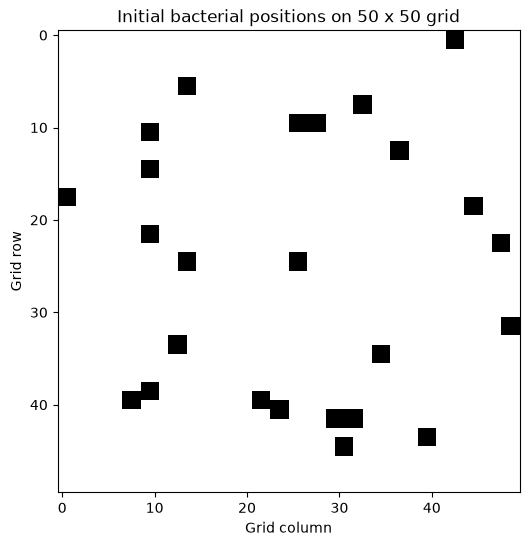

In [5]:
# Create the spatial grid and place bacteria
def initialise_bacteria(seed, n_bacteria=25):
    rng = np.random.default_rng(seed)
    grid = np.zeros((50, 50), dtype=int)
    positions = []
    for bacterium_id in range(1, n_bacteria + 1):
        placed = False
        for attempt in range(10000):
            x = rng.integers(0, 49)
            y = rng.integers(0, 49)
            # Check that the 2 x 2 space is empty
            if np.all(grid[x:x+2, y:y+2] == 0):
                grid[x:x+2, y:y+2] = bacterium_id
                positions.append((x, y))
                placed = True
                break
        if not placed:
            raise RuntimeError("Could not place bacteria")
    return grid, positions


# Test the function
grid, positions = initialise_bacteria(
    seed=1000,
    n_bacteria=25)
print("Number of bacteria:", len(positions))
plt.figure(figsize=(6, 6))
plt.imshow(grid > 0, cmap="Greys", interpolation="nearest")
plt.title("Initial bacterial positions on 50 x 50 grid")
plt.xlabel("Grid column")
plt.ylabel("Grid row")
plt.show()

This section introduces bacterial movement within the 50 × 50 spatial grid. Each bacterium can move one lattice position upwards, downwards, left or right. Before movement occurs, the code checks that the new position is inside the grid and does not overlap another bacterium.

This demonstrates the spatial movement rules described in the supplementary information. However, it is currently a movement test rather than the complete stochastic diffusion model.

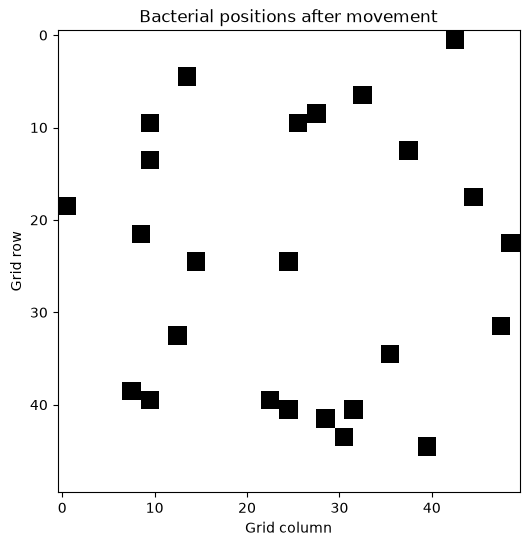

Bacteria before: 25
Bacteria after: 25


In [6]:
# Move bacteria around the grid
# Initial test of spatial diffusion
def move_bacteria(grid, positions, seed=1001):
    rng = np.random.default_rng(seed)
    new_grid = grid.copy()
    new_positions = positions.copy()

    # Four possible movement directions
    directions = [
        (-1, 0),
        (1, 0),
        (0, -1),
        (0, 1) ]
    for i, (x, y) in enumerate(positions):
        dx, dy = directions[
            rng.integers(0, len(directions)) ]
        new_x = x + dx
        new_y = y + dy

        # Keep bacteria inside the grid
        if not (0 <= new_x <= 48 and
                0 <= new_y <= 48):
            continue

        # Temporarily remove the bacterium
        bacterium_id = i + 1
        new_grid[x:x+2, y:y+2] = 0

        # Check whether new position is free
        if np.all(
            new_grid[new_x:new_x+2,
                     new_y:new_y+2] == 0 ):
            new_grid[
                new_x:new_x+2,
                new_y:new_y+2
            ] = bacterium_id

            new_positions[i] = (
                new_x, new_y   )
        else:
            # Restore original position
            new_grid[x:x+2, y:y+2] = bacterium_id
    return new_grid, new_positions

# Test bacterial movement
moved_grid, moved_positions = move_bacteria(
    grid, positions)
plt.figure(figsize=(6, 6))
plt.imshow(
    moved_grid > 0,
    cmap="Greys",
    interpolation="nearest")
plt.title("Bacterial positions after movement")
plt.xlabel("Grid column")
plt.ylabel("Grid row")
plt.show()
print("Bacteria before:", len(positions))
print("Bacteria after:", len(moved_positions))

introduces polymers and signalling molecules into the 50 × 50 spatial grid. Polymers and signals are represented using separate NumPy arrays, which record the number of molecules at each lattice position. Unlike bacteria, multiple polymers and signals can occupy the same site.

Total polymers: 3000
Total signals: 10000


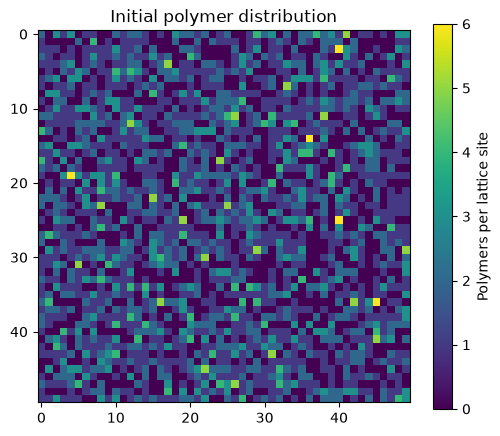

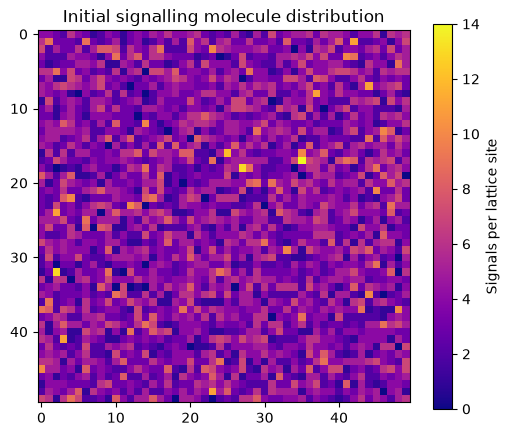

In [7]:
# Initialise polymers and signalling molecules
def initialise_molecules(seed=1000,
                         n_polymers=3000,
                         n_signals=10000):
    rng = np.random.default_rng(seed)

    # Separate arrays record how many molecules
    # occupy each lattice position.
    polymer_grid = np.zeros((50, 50), dtype=int)
    signal_grid = np.zeros((50, 50), dtype=int)

    # Randomly place polymers
    polymer_positions = rng.integers(
        0, 50, size=(n_polymers, 2) )
    for x, y in polymer_positions:
        polymer_grid[x, y] += 1

    # Randomly place signals
    signal_positions = rng.integers(
        0, 50, size=(n_signals, 2) )
    for x, y in signal_positions:
        signal_grid[x, y] += 1
    return polymer_grid, signal_grid


# Test initialisation
polymer_grid, signal_grid = initialise_molecules()
print("Total polymers:", polymer_grid.sum())
print("Total signals:", signal_grid.sum())
plt.figure(figsize=(6, 5))
plt.imshow(polymer_grid, cmap="viridis")
plt.colorbar(label="Polymers per lattice site")
plt.title("Initial polymer distribution")
plt.show()
plt.figure(figsize=(6, 5))
plt.imshow(signal_grid, cmap="plasma")
plt.colorbar(label="Signals per lattice site")
plt.title("Initial signalling molecule distribution")
plt.show()

This section models the stochastic movement of polymers and signalling molecules between neighbouring lattice positions. Molecules may move upwards, downwards, left or right, with movement probabilities determined by their diffusion rates.
The polymer diffusion rate is 0.01 and the signal diffusion rate is 0.05, meaning signals move more frequently than polymers in this implementation. The total number of each molecule type is conserved during diffusion.

In [8]:
# Diffusion of polymers and signals
# One illustrative stochastic movement interval
def diffuse_molecules(molecule_grid, diffusion_rate,
                      dt=1, seed=1001):
    rng = np.random.default_rng(seed)
    new_grid = np.zeros_like(molecule_grid)

    # Four possible movement directions
    directions = [
        (-1, 0), (1, 0),
        (0, -1), (0, 1) ]
    for x in range(50):
        for y in range(50):
            count = molecule_grid[x, y]
            if count == 0:
                continue

            # Probability of attempting movement
            probability = min(1.0, 4 * diffusion_rate * dt)
            moving = rng.binomial(count, probability)
            staying = count - moving
            new_grid[x, y] += staying

            # Random movement to neighbouring sites
            for _ in range(moving):
                dx, dy = directions[rng.integers(0, 4)]
                nx = x + dx
                ny = y + dy
                if 0 <= nx < 50 and 0 <= ny < 50:
                    new_grid[nx, ny] += 1
                else:
                    new_grid[x, y] += 1
    return new_grid


# Test diffusion
polymer_after = diffuse_molecules(
    polymer_grid, D_P, dt=1, seed=1001
)
signal_after = diffuse_molecules(
    signal_grid, D_S, dt=1, seed=1002
)
print("Polymers before:", polymer_grid.sum())
print("Polymers after:", polymer_after.sum())
print("Signals before:", signal_grid.sum())
print("Signals after:", signal_after.sum())

Polymers before: 3000
Polymers after: 3000
Signals before: 10000
Signals after: 10000


This cell defines the binding parameters and available binding sites for bacteria, polymers and signalling molecules. The supplementary model includes reversible bacteria–signal, polymer–bacteria and polymer–signal interactions. Each bacterium has 120 polymer-binding sites and 60 signal-binding sites, while each polymer has two bacteria-binding sites and five signal-binding sites.

In [9]:
# Reversible binding parameters
# Published signal-bacteria binding rates
K_BS = 0.5
K_BS_ON = 0.001
K_BS_OFF = 0.002

# Binding sites
B_POLYMER_SITES = 120
B_SIGNAL_SITES = 60
P_BACTERIA_SITES = 2
P_SIGNAL_SITES = 5

# Polymer crowding threshold
P_C = 10

# Example P3 affinities
K_PB = 5
K_PS = 10

# Assumed forward rates for polymer binding
# The affinities alone do not determine both rates
K_PB_ON = 0.001
K_PS_ON = 0.001
K_PB_OFF = K_PB_ON / K_PB
K_PS_OFF = K_PS_ON / K_PS
print("Bacteria-signal affinity:", K_BS)
print("Polymer-bacteria affinity:", K_PB)
print("Polymer-signal affinity:", K_PS)

Bacteria-signal affinity: 0.5
Polymer-bacteria affinity: 5
Polymer-signal affinity: 10


This function demonstrates stochastic binding and unbinding between molecules and available binding sites. Binding reduces the number of free molecules and free binding sites, while unbinding releases them.
The example tests signal binding to bacterial receptors using the published forward and reverse rates. The function is an approximation and does not yet account for the local spatial distribution of reactants or the complete Gillespie event-selection procedure.

In [10]:
# Simplified reversible binding test
def reversible_binding(free_sites, free_molecules,
                       bound, k_on, k_off,
                       dt=1, seed=1003):
    rng = np.random.default_rng(seed)

    # Probability that an available pair binds
    p_bind = 1 - np.exp(-k_on * dt)

    # Probability that a bound pair unbinds
    p_unbind = 1 - np.exp(-k_off * dt)

    # Simplified number of possible binding pairs
    possible_pairs = min(
        free_sites, free_molecules )
    new_bindings = rng.binomial(
        possible_pairs, p_bind )
    new_unbindings = rng.binomial(
        bound, p_unbind  )
    free_sites = (
        free_sites - new_bindings
        + new_unbindings  )
    free_molecules = (
        free_molecules - new_bindings
        + new_unbindings )
    bound = (
        bound + new_bindings
        - new_unbindings )
    return free_sites, free_molecules, bound

# Test bacteria-signal binding
free_sites = 60
free_signals = 100
bound_signals = 0
for step in range(100):
    free_sites, free_signals, bound_signals = (
        reversible_binding(
            free_sites,
            free_signals,
            bound_signals,
            K_BS_ON,
            K_BS_OFF,
            dt=1,
            seed=1003 + step   ) )
print("Free bacterial signal sites:", free_sites)
print("Free signalling molecules:", free_signals)
print("Bound signals:", bound_signals)

Free bacterial signal sites: 52
Free signalling molecules: 92
Bound signals: 8


This cell tests three reversible interactions: bacteria–signal, polymer–bacteria and polymer–signal binding. These interactions are important because bacterial binding can promote clustering, whereas polymer–signal binding can reduce the availability of free signalling molecules.

The code tests the reactions separately using example molecule counts.

In [11]:
# Compare the three reversible binding reactions
reactions = {
    "Bacteria-signal": (
        60, 100, 0,
        K_BS_ON, K_BS_OFF  ),
    "Polymer-bacteria": (
        120, 20, 0,
        K_PB_ON, K_PB_OFF ),
    "Polymer-signal": (
        100, 100, 0,
        K_PS_ON, K_PS_OFF  )}
for name, values in reactions.items():
    free_sites, free_molecules, bound, k_on, k_off = values
    for step in range(100):
        free_sites, free_molecules, bound = (
            reversible_binding(
                free_sites,
                free_molecules,
                bound,
                k_on,
                k_off,
                seed=2000 + step      )   )
    print(name)
    print("  Bound complexes:", bound)
    print("  Free sites:", free_sites)
    print()

Bacteria-signal
  Bound complexes: 8
  Free sites: 52

Polymer-bacteria
  Bound complexes: 2
  Free sites: 118

Polymer-signal
  Bound complexes: 13
  Free sites: 87



This section models the timing of bacterial division using a triangular probability distribution. The supplementary information reports a mean division time of 15,000 arbitrary units and a distribution width of 20,000 units.

The code samples a division time for each of the 25 starting bacteria and displays their distribution. A symmetric triangular distribution between 5,000 and 25,000 units is assumed.

Number of bacteria: 25
Mean sampled division time: 14439.84


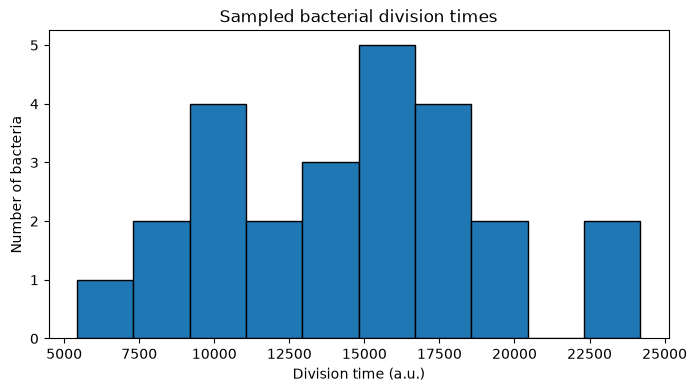

In [12]:
# Bacterial growth and division
# Test of the reported division-time distribution
import numpy as np
import matplotlib.pyplot as plt
def generate_division_times(n_bacteria=25, seed=1004):
    rng = np.random.default_rng(seed)

    # Triangular distribution:
    # minimum = 5000, mode = 15000, maximum = 25000
    division_times = rng.triangular(
        left=5000,
        mode=15000,
        right=25000,
        size=n_bacteria )
    return division_times
division_times = generate_division_times()
print("Number of bacteria:", len(division_times))
print("Mean sampled division time:",
      round(division_times.mean(), 2))
plt.figure(figsize=(8, 4))
plt.hist(division_times, bins=10, edgecolor="black")
plt.xlabel("Division time (a.u.)")
plt.ylabel("Number of bacteria")
plt.title("Sampled bacterial division times")
plt.show()

This section implements bacterial division within the spatial grid. When a bacterium divides, the function searches neighbouring positions for an available 2 × 2 area. If a suitable space is found, a daughter bacterium is created and assigned a new ID.

The code prevents bacterial overlap, keeps cells within the 50 × 50 grid and limits the population to 80 bacteria, as specified in the supplementary information.

This is a test of daughter-cell placement.

Division successful: True
Bacteria before: 25
Bacteria after: 26


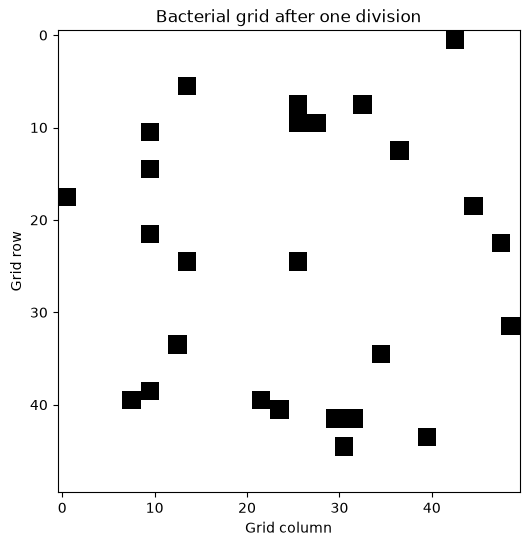

In [13]:
# Bacterial division on the spatial grid
def divide_bacterium(grid, positions, bacterium_index):
    new_grid = grid.copy()
    new_positions = positions.copy()

    # Maximum bacterial population
    if len(new_positions) >= 80:
        return new_grid, new_positions, False

    # Find the parent bacterium
    x, y = new_positions[bacterium_index]

    # Possible neighbouring positions
    # A bacterium occupies 2 x 2 lattice sites
    neighbours = [
        (x - 2, y),
        (x + 2, y),
        (x, y - 2),
        (x, y + 2)]
    for nx, ny in neighbours:

        # Check grid boundaries
        if not (0 <= nx <= 48 and 0 <= ny <= 48):
            continue

        # Check for an empty 2 x 2 space
        if np.all(new_grid[nx:nx+2, ny:ny+2] == 0):

            # Assign a new bacterial ID
            new_id = len(new_positions) + 1
            new_grid[nx:nx+2, ny:ny+2] = new_id
            new_positions.append((nx, ny))
            return new_grid, new_positions, True

    # No suitable neighbouring space
    return new_grid, new_positions, False

# Test one bacterial division
division_grid, division_positions, success = (
    divide_bacterium(
        grid,
        positions,
        bacterium_index=0))
print("Division successful:", success)
print("Bacteria before:", len(positions))
print("Bacteria after:", len(division_positions))

plt.figure(figsize=(6, 6))
plt.imshow(
    division_grid > 0,
    cmap="Greys",
    interpolation="nearest")
plt.title("Bacterial grid after one division")
plt.xlabel("Grid column")
plt.ylabel("Grid row")
plt.show()

This section connects bacterial division to the simulation clock. Each bacterium is assigned a division time sampled from a triangular distribution with a mean of 15,000 arbitrary units. When a scheduled division time is reached, the model attempts to place a daughter bacterium in an available neighbouring 2 × 2 space.
Successful divisions increase the bacterial population, and both parent and daughter cells receive new division times. The population cannot exceed 80 bacteria.
The graph shows how bacterial population size changes during the 30,000-unit simulation. This is a simplified scheduled-growth model rather than the complete Gillespie simulation.

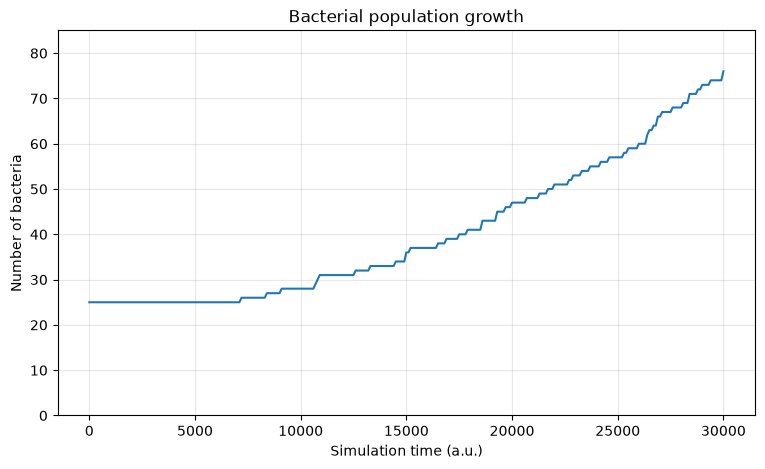

Initial population: 25
Final population: 76


In [14]:
# Schedule bacterial division over time
def simulate_bacterial_growth(seed=1005):
    rng = np.random.default_rng(seed)
    
    # Start with 25 bacteria
    growth_grid, growth_positions = initialise_bacteria(
        seed=seed,
        n_bacteria=25  )

    # Assign a division time to each bacterium
    next_divisions = list(
        rng.triangular(
            5000, 15000, 25000,
            size=25     ) )
    times = np.arange(0, 30001, 100)
    populations = []
    for time in times:

        # Check bacteria due to divide
        for i in range(len(growth_positions)):
            if time >= next_divisions[i]:
                growth_grid, growth_positions, success = (
                    divide_bacterium(
                        growth_grid,
                        growth_positions,
                        bacterium_index=i ))

                if success:
                    # Give daughter its own division time
                    daughter_time = time + rng.triangular(
                        5000, 15000, 25000)
                    next_divisions.append(daughter_time)

                    # Schedule parent's next division
                    next_divisions[i] = time + rng.triangular(
                        5000, 15000, 25000)
                else:
                    # Try again at next output time
                    next_divisions[i] = time + 100
        populations.append(len(growth_positions))
    return times, np.array(populations)

# Run growth simulation
growth_times, population = simulate_bacterial_growth()
plt.figure(figsize=(9, 5))
plt.plot(growth_times, population)
plt.xlabel("Simulation time (a.u.)")
plt.ylabel("Number of bacteria")
plt.title("Bacterial population growth")
plt.ylim(0, 85)
plt.grid(alpha=0.3)
plt.show()
print("Initial population:", population[0])
print("Final population:", population[-1])

This section models how protein expression changes in response to signalling molecules detected by bacteria. When the sensed signal level exceeds the current expression level, proteins are synthesised at a rate of 0.05. When expression exceeds the sensed signal level, proteins degrade over time.

The supplementary information prints a degradation parameter of −0.01, although the equation already contains a negative sign. To represent protein breakdown, this implementation uses a positive decay magnitude of 0.01.

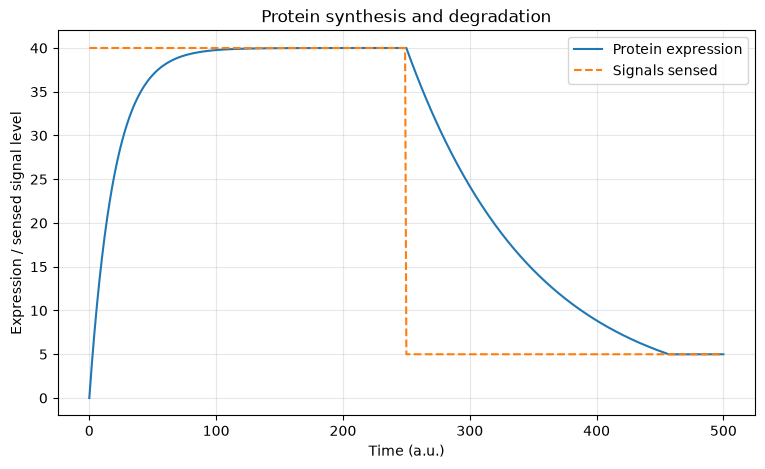

In [23]:
# Protein expression parameters
K_SYN = 0.05
K_DEGRAD = 0.01  # Positive decay magnitude
DT = 1.0
def update_expression(bs_sense, bs_express, dt=DT):
    if bs_sense > bs_express:
        # Protein synthesis
        change = K_SYN * (
            bs_sense - bs_express
        ) * dt
        bs_express += change
    else:
        # Protein degradation
        change = K_DEGRAD * bs_express * dt
        bs_express -= change
    return max(0, bs_express)

# Test protein expression over time
time_points = np.arange(0, 501, DT)
expression = np.zeros(len(time_points))

# Example: signals detected initially, then removed
sensed_signals = np.where(
    time_points < 250, 40.0, 5.0)
for i in range(1, len(time_points)):
    expression[i] = update_expression(
        sensed_signals[i-1],
        expression[i-1]  )
plt.figure(figsize=(9, 5))
plt.plot(time_points, expression,
         label="Protein expression")
plt.plot(time_points, sensed_signals,
         "--", label="Signals sensed")
plt.xlabel("Time (a.u.)")
plt.ylabel("Expression / sensed signal level")
plt.title("Protein synthesis and degradation")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

This section converts protein expression into predicted luminescence. The model uses a scale factor of 2,500 and strain-specific parameters of 38 for MM32 and 15 for BB170.
The luminescence equation printed in the supplementary information appears mathematically inconsistent because it simplifies to a constant.
This alternative is an assumption and cannot be treated as the exact published equation.
The graph shows how changes in protein expression may lead to changes in luminescence over time.

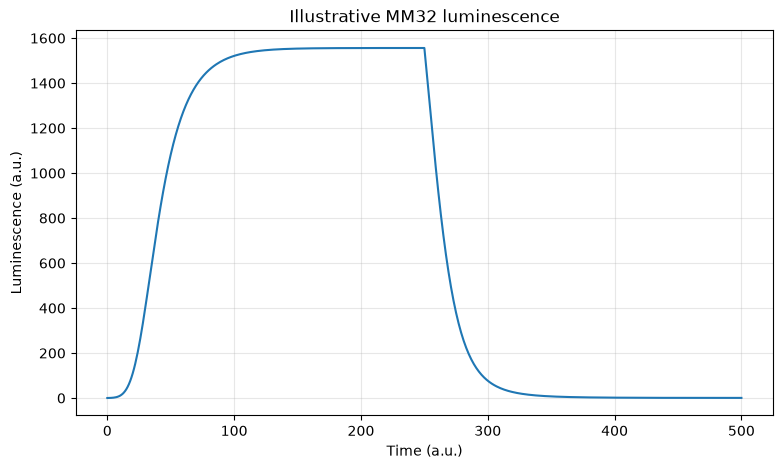

In [24]:
# Luminescence calculation
# Illustrative alternative to ambiguous printed equation
SCALE = 2500
BS_C_MM32 = 38
BS_C_BB170 = 15
def calculate_luminescence(bs_express, strain="MM32"):
    if strain == "MM32":
        threshold = BS_C_MM32
    elif strain == "BB170":
        threshold = BS_C_BB170
    else:
        raise ValueError("Unknown bacterial strain")

    # Assumed sigmoid response
    delta = 0.25 * (bs_express - threshold)
    luminescence = SCALE / (
        1 + np.exp(-np.clip(delta, -50, 50)))
    return luminescence

# Test luminescence from expression values
light = calculate_luminescence(
    expression, strain="MM32")
plt.figure(figsize=(9, 5))
plt.plot(time_points, light)
plt.xlabel("Time (a.u.)")
plt.ylabel("Luminescence (a.u.)")
plt.title("Illustrative MM32 luminescence")
plt.grid(alpha=0.3)
plt.show()

This section connects the spatial grid to bacterial signal detection. The code counts signalling molecules in the four lattice sites occupied by each bacterium, producing a local signal count for each cell.
This is an initial approximation of signal detection. In the published model, signals must bind to available bacterial receptor sites before influencing protein expression. The local signal count therefore does not yet represent the number of receptor-bound signals.

In [25]:
# Connect local signals to bacterial protein expression
# This is a demonstration, not yet the full Gillespie model.
def calculate_local_signals(positions, signal_grid):
    local_signals = []
    for x, y in positions:
        # Count signals in the bacterium's 2 x 2 area
        count = signal_grid[x:x+2, y:y+2].sum()
        local_signals.append(count)
    return np.array(local_signals, dtype=float)

# Use the original 25 bacteria and initial signal grid
local_signals = calculate_local_signals(
    positions, signal_grid)
print("Number of bacteria:", len(local_signals))
print("Signals near first five bacteria:", local_signals[:5])
print("Average local signals:", local_signals.mean())

Number of bacteria: 25
Signals near first five bacteria: [22. 23. 15. 16. 17.]
Average local signals: 16.4


This section updates protein expression separately for each bacterium based on its local signal count. Protein synthesis occurs when the local signal level exceeds expression, while degradation occurs when expression exceeds the signal level.
The calculation demonstrates how spatial differences in signal availability could produce differences in protein expression. However, the published model uses receptor-bound signals rather than the total number of nearby free signals.

In [26]:
# Update expression separately for each bacterium
def update_all_expression(local_signals, expression_levels, dt=1):
    updated = np.zeros_like(expression_levels, dtype=float)
    for i in range(len(local_signals)):
        updated[i] = update_expression(
            bs_sense=local_signals[i],
            bs_express=expression_levels[i],
            dt=dt )
    return updated

# Initially no expressed protein
expression_levels = np.zeros(len(positions))

# Demonstrate 100 expression updates
for step in range(100):
    expression_levels = update_all_expression(
        local_signals,
        expression_levels,
        dt=1)
print("Expression levels for first five bacteria:")
print(np.round(expression_levels[:5], 2))

Expression levels for first five bacteria:
[21.87 22.86 14.91 15.91 16.9 ]


This section calculates the predicted luminescence of each bacterium using its estimated protein expression level. Individual luminescence values are summed to estimate total light production and averaged to calculate the mean per bacterium.
The calculation uses the previously defined illustrative luminescence equation. It demonstrates how local signalling differences can affect predicted light production but does not yet reproduce the published model's full signal-binding dynamics.

Total MM32 luminescence: 485.62
Mean luminescence per bacterium: 19.42


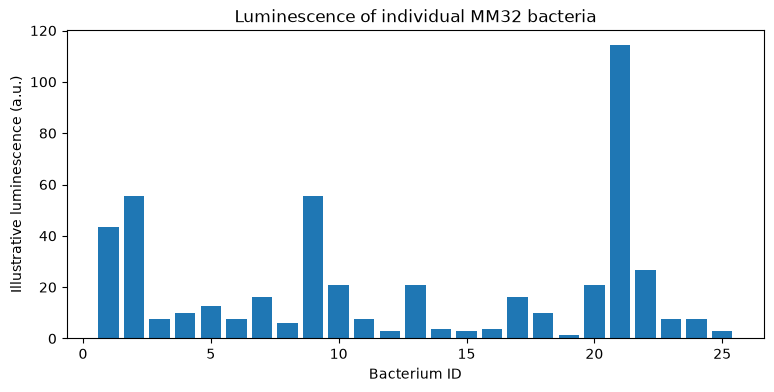

In [27]:
# Calculate luminescence from all bacteria
individual_luminescence = calculate_luminescence(
    expression_levels,
    strain="MM32")
total_luminescence = individual_luminescence.sum()
mean_luminescence = individual_luminescence.mean()
print("Total MM32 luminescence:",
      round(total_luminescence, 2))
print("Mean luminescence per bacterium:",
      round(mean_luminescence, 2))
plt.figure(figsize=(9, 4))
plt.bar(
    np.arange(1, len(individual_luminescence) + 1),
    individual_luminescence)
plt.xlabel("Bacterium ID")
plt.ylabel("Illustrative luminescence (a.u.)")
plt.title("Luminescence of individual MM32 bacteria")
plt.show()

This section combines bacterial movement, signal diffusion, local signal detection, protein expression and luminescence calculation into a single simulation loop.

The simulation begins with 25 bacteria and 10,000 signalling molecules on a 50 × 50 grid. At each step, bacteria move, signalling molecules diffuse, and the model updates protein expression based on the local signal concentration.

This is an initial integration test 

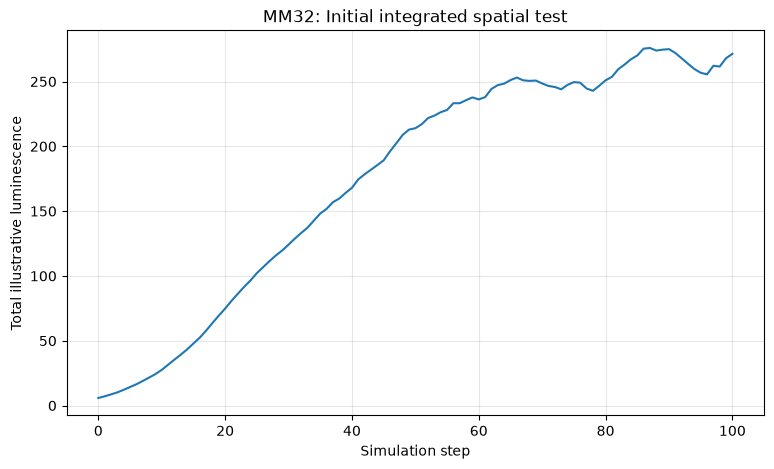

In [28]:
# Integrated spatial simulation - first test
# Uses existing functions from earlier cells
def run_spatial_test(seed=1000, steps=100):

    # Initialise bacteria and molecules
    current_grid, current_positions = initialise_bacteria(
        seed=seed,
        n_bacteria=25 )
    _, current_signals = initialise_molecules(
        seed=seed + 1,
        n_polymers=0,
        n_signals=10000 )

    # Protein expression for each bacterium
    current_expression = np.zeros(25)
    times = []
    total_light = []
    for step in range(steps + 1):

        # Count nearby signals
        sensed = calculate_local_signals(
            current_positions,
            current_signals  )

        # Update protein expression
        current_expression = update_all_expression(
            sensed,
            current_expression,
            dt=1  )

        # Calculate total luminescence
        light = calculate_luminescence(
            current_expression,
            strain="MM32"
        ).sum()
        times.append(step)
        total_light.append(light)

        # Move bacteria one step
        if step < steps:
            current_grid, current_positions = move_bacteria(
                current_grid,
                current_positions,
                seed=seed + 100 + step)

            # Diffuse signals
            current_signals = diffuse_molecules(
                current_signals,
                D_S,
                dt=1,
                seed=seed + 200 + step)
    return np.array(times), np.array(total_light)

# Run the first integrated test
test_times, test_light = run_spatial_test()
plt.figure(figsize=(9, 5))
plt.plot(test_times, test_light)
plt.xlabel("Simulation step")
plt.ylabel("Total illustrative luminescence")
plt.title("MM32: Initial integrated spatial test")
plt.grid(alpha=0.3)
plt.show()

In [22]:
def simulate(strain, polymer_amount,
             K_PB, K_PS, seed,
             initial_bacteria=25,
             doubling_time=15000):
    rng = np.random.default_rng(seed)

    # Approximate bacterial growth
    bacteria = initial_bacteria * 2**(
        TIMES / doubling_time)
    bacteria = np.minimum(bacteria, MAX_BACTERIA)

    # Signal availability
    if strain == "MM32":
        signals = MM32_SIGNALS * np.exp(
            -TIMES / 22000
        )
        threshold = 38
    else:
        signals = 0.005 * bacteria * TIMES
        threshold = 15

    # Approximate clustering
    clustering = (
        K_PB * polymer_amount / 3000 )

    # Approximate signal sequestration
    sequestration = (
        1 + K_PS * polymer_amount / 3000 )
    effective_signals = (
        signals * (1 + 0.3 * clustering)
        / sequestration )

    # Approximate signal detection
    sensed = (
        60 * effective_signals
        / (effective_signals + 5000)  )

    # Illustrative luminescence response
    lum = 2500 / (
        1 + np.exp(
            np.clip(
                -0.25 * (sensed - threshold),
                -50, 50       )    ) )
    lum *= bacteria
   
    # Add random variation
    noise = rng.normal(
        0, 0.04, size=len(TIMES)
    )
    lum = lum * np.maximum(0, 1 + noise)
    return lum

This function repeats each simulation 10 times using the recorded random seeds. The results are stored in an array so that the mean and standard deviation can be calculated. In this simplified model, the runs differ through added random noise rather than independent stochastic binding, diffusion and growth events.

In [16]:
def run_replicates(strain, polymer_amount,
                   K_PB, K_PS,
                   initial_bacteria=25,
                   doubling_time=15000):
    runs = []
    for seed in SEEDS:
        result = simulate(
            strain,
            polymer_amount,
            K_PB,
            K_PS,
            seed,
            initial_bacteria,
            doubling_time)
        runs.append(result)
    return np.array(runs)

This function calculates the mean luminescence and standard deviation across the 10 runs. The line represents the mean response, while the shaded area represents variation between runs.

In [17]:
def plot_runs(runs, label):
    mean = runs.mean(axis=0)
    std = runs.std(axis=0, ddof=1)
    plt.plot(TIMES, mean, label=label)
    plt.fill_between(
        TIMES,
        mean - std,
        mean + std,
        alpha=0.15)

This simulation compares MM32 luminescence with no polymer against treatment with P1 at a concentration of 3,000 arbitrary units. The purpose is to investigate whether polymer-induced bacterial clustering increases predicted luminescence. The graph shows the mean of 10 runs for each condition, with standard deviation bands. These are exploratory predictions rather than reproduced published curves.

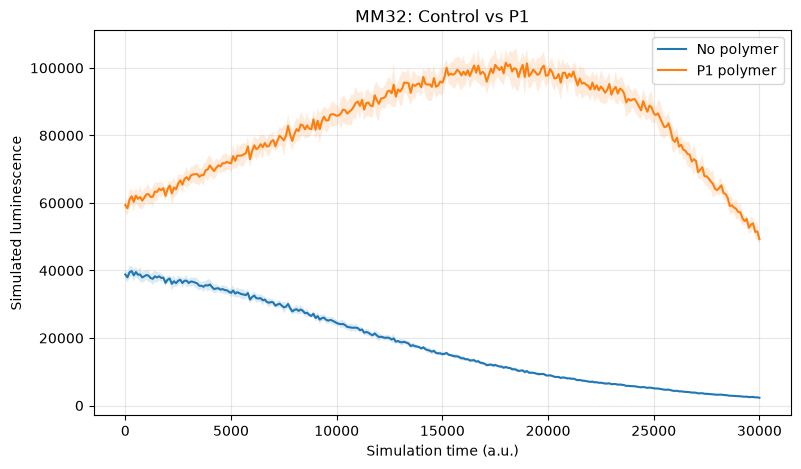

In [18]:
# No-polymer control
control = run_replicates(
    "MM32", 0, 0, 0)

# P1 polymer treatment
p1 = run_replicates(
    "MM32", 3000, 5, 0)
plt.figure(figsize=(9, 5))
plot_runs(control, "No polymer")
plot_runs(p1, "P1 polymer")
plt.xlabel("Simulation time (a.u.)")
plt.ylabel("Simulated luminescence")
plt.title("MM32: Control vs P1")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

This cell compares the predicted MM32 luminescence responses for the control, P1, P2 and P3 polymers. It explores how bacterial binding and signal sequestration influence the response. The comparison uses the three example polymer affinity settings rather than the complete 25-combination affinity sweep reported in the supplementary information.

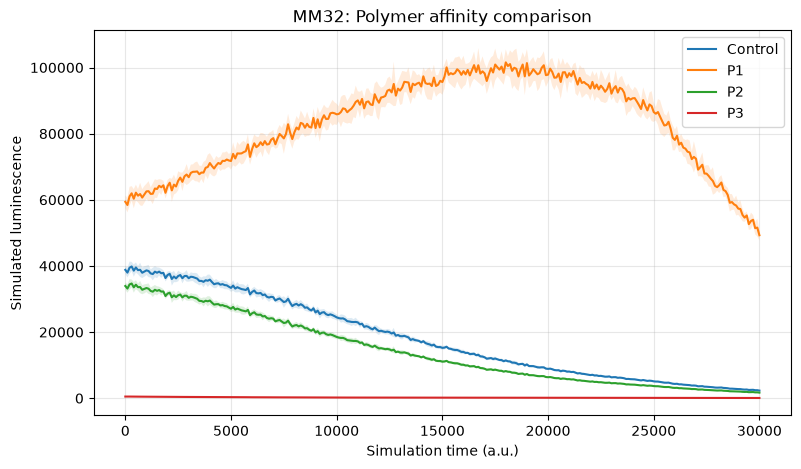

In [19]:
plt.figure(figsize=(9, 5))
for name, (kpb, kps) in POLYMERS.items():
    amount = (
        0 if name == "Control"
        else POLYMER_AMOUNT )
    runs = run_replicates(
        "MM32", amount, kpb, kps  )

    plot_runs(runs, name)
plt.xlabel("Simulation time (a.u.)")
plt.ylabel("Simulated luminescence")
plt.title("MM32: Polymer affinity comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

This cell explores BB170 luminescence under different polymer conditions. Unlike MM32, BB170 produces its own signalling molecules. The simplified model approximates signal accumulation over time and predicts how polymer binding may influence light production. The results can be compared qualitatively with supplementary Figures S40–S42, but the model does not yet implement their full growth and spatial conditions.

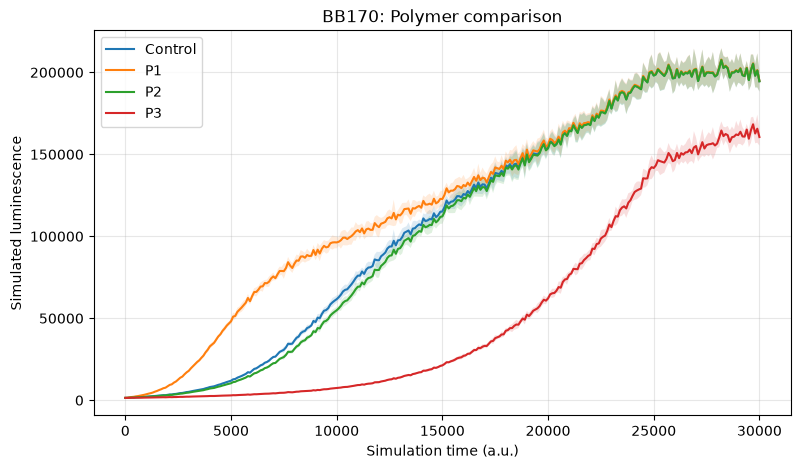

In [20]:
plt.figure(figsize=(9, 5))
for name, (kpb, kps) in POLYMERS.items():
    amount = (
        0 if name == "Control"
        else POLYMER_AMOUNT )
    runs = run_replicates(
        "BB170", amount, kpb, kps )
    plot_runs(runs, name)
plt.xlabel("Simulation time (a.u.)")
plt.ylabel("Simulated luminescence")
plt.title("BB170: Polymer comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

This cell records the random seeds used for reproducibility and saves the MM32 simulation results in CSV format. The files contain the mean luminescence and standard deviation for the no-polymer and P1 conditions, allowing the analysis to be repeated and checked.

In [21]:
# Save random seeds
seed_table = pd.DataFrame({
    "Run": np.arange(1, 11),
    "Random seed": SEEDS})
display(seed_table)
seed_table.to_csv(
    "random_seeds.csv",
    index=False)

# Save Stage 1 mean results
results = pd.DataFrame({
    "Time": TIMES,
    "MM32_Control_Mean": control.mean(axis=0),
    "MM32_P1_Mean": p1.mean(axis=0),
    "MM32_Control_SD": control.std(axis=0, ddof=1),
    "MM32_P1_SD": p1.std(axis=0, ddof=1)})
results.to_csv(
    "MM32_results.csv",
    index=False)
print("Random seeds and MM32 results saved.")

,Run,Random seed
0,1,1000
1,2,1001
2,3,1002
3,4,1003
4,5,1004
5,6,1005
6,7,1006
7,8,1007
8,9,1008
9,10,1009


Random seeds and MM32 results saved.


AI Usage Declaration
OpenAI ChatGPT was used to assist with the development and organisation of the Python code for section 3. AI assistance included generating example simulation functions, explaining the purpose of each code section, and helping structure the Jupyter Notebook.
The use of AI has been acknowledged to maintain transparency about its contribution to this assignment.